# AI-HPC Hybrid Solver: 2D Poisson with Red-Black Gauss-Seidel + Decoder Transformer

**Idea.** Run a classical iterative solver on the GPU up to a *checkpoint*, then let a causal (decoder-only) Transformer
use the saved iteration history to skip the slow tail of convergence. HPC supplies the training data and the
ground truth; the AI is judged against both the HPC result and simple numerical baselines.

**Pipeline**
1. Sequential Gauss-Seidel baselines (pure Python, and compiled Numba CPU)
2. Red-Black Gauss-Seidel on the GPU (Numba CUDA), plus a grid-size scaling study
3. Dataset: 100 CUDA trajectories of varied Poisson problems
4. Decoder-only Transformer (causal masked self-attention), one token per saved iteration state
5. Evaluation from the checkpoint: autoregressive rollout and one-shot "jump to the converged state"
6. Hybrid timing: CUDA to checkpoint + AI jump + CUDA warm-start finish

**Design choices**
- Every trajectory is normalised by the checkpoint state's amplitude, so problems of different amplitude are comparable.
- The model predicts *changes* (next-step increment and remaining distance to the converged state) in an `asinh` space.
  Predictions are added to the current state, so "do nothing" is already a reasonable answer.
- Residuals are *relative* (divided by max|f|), so the checkpoint is amplitude independent, and all solvers stop on the same true residual.
- Baselines: pure-Python and compiled Numba CPU solvers, plus a grid-size scaling study that shows where the GPU actually helps.
- The AI is compared with simple numerical baselines: "freeze at checkpoint" and Aitken-style extrapolation.
- Hybrid timing is measured, and the finish is a warm-started solve to the same tolerance as the full CUDA run.
- Training uses GPU-resident tensors, batch size 64 and early stopping, so it takes minutes.

## 0. Setup and configuration

In [1]:
import os, math, time, json, copy, warnings
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import numba
from numba import cuda
warnings.filterwarnings('ignore')

QUICK = int(os.environ.get('AIHPC_QUICK', '0'))   # 0 = full run (use this on Kaggle); 1/2 = tiny smoke tests

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
try:
    CUDA_OK = bool(cuda.is_available())
except Exception:
    CUDA_OK = False

# ---- problem / solver
N            = 50        # interior grid points per side
TOL          = 1e-6      # final tolerance on the RELATIVE residual  max|Au-f| / max|f|
CHKPT_R      = 1e-3      # HPC -> AI hand-off: first snapshot with relative residual <= this
SNAP_EVERY   = 10        # iterations between residual checks / saved snapshots
MAX_ITER     = 100000
N_TRAJ       = 100       # training + validation + test trajectories (80/10/10 split)

# ---- model / training
SEQ_LEN      = 16        # snapshots of context given to the Transformer
D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT = 256, 4, 4, 512, 0.1
EPOCHS, PATIENCE, BATCH = 100, 20, 64
LR, WD, WARMUP_EPOCHS   = 5e-4, 1e-2, 3
W_NEXT, W_FINAL, W_RES  = 1.0, 1.0, 0.1   # loss weights: next-step increment, jump-to-final, log-residual (aux)
W_PRE        = 0.3       # weight of positions BEFORE the checkpoint (positions at/after it get weight 1)
C_ASINH      = 1e-4      # asinh scale: targets are asinh(change / C); resolves changes down to ~1e-4 of the amplitude
CLAMP        = 10.0      # clamp on network outputs before sinh()
RUN_PY_BASELINE = True   # pure-Python sequential GS takes ~15-30 s

if QUICK:
    N, N_TRAJ, SEQ_LEN = 24, (14 if QUICK == 1 else 60), 8
    EPOCHS, PATIENCE, WARMUP_EPOCHS = (2 if QUICK == 1 else 30), 10, 1
    if QUICK == 1: D_MODEL, D_FF, N_LAYERS = 64, 128, 2

OUT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
RESULTS = {}

print(f'torch {torch.__version__} | numba {numba.__version__} | torch device: {DEVICE} | numba CUDA usable: {CUDA_OK}')
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0), f'| VRAM {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
if not CUDA_OK:
    print('WARNING: no CUDA device for Numba. A NumPy fallback is used (works, but timings are not GPU timings).')
print(f'grid {N}x{N} | TOL {TOL} | CHKPT_R {CHKPT_R} | trajectories {N_TRAJ} | context {SEQ_LEN} | quick={QUICK}')

torch 2.10.0+cu128 | numba 0.60.0 | torch device: cuda | numba CUDA usable: True
GPU: Tesla T4 | VRAM 15.6 GB
grid 50x50 | TOL 1e-06 | CHKPT_R 0.001 | trajectories 100 | context 16 | quick=0


## 1. Problem definition

Solve $\nabla^2 u = f$ on $[0,1]^2$ with zero Dirichlet boundaries (5-point stencil, $h = 1/(N+1)$).

**Standard problem:** $f = -2\pi^2 \sin(\pi x)\sin(\pi y)$, exact solution $u = \sin(\pi x)\sin(\pi y)$.
Note that the *discrete* solution differs from the analytical one by a discretisation error of about $\pi^2 h^2/12 \approx 3\times10^{-4}$,
so no iterative solver can get below that against the analytical solution.

**Training problems:** random superpositions of sine modes (mode numbers 1-3, random signs and amplitudes), each with a known exact solution.
60% of them contain the (1,1) mode (the slowest-converging one) together with 1-3 other modes. A *pure* (1,1) problem is never generated,
so the standard problem is not in the training set.

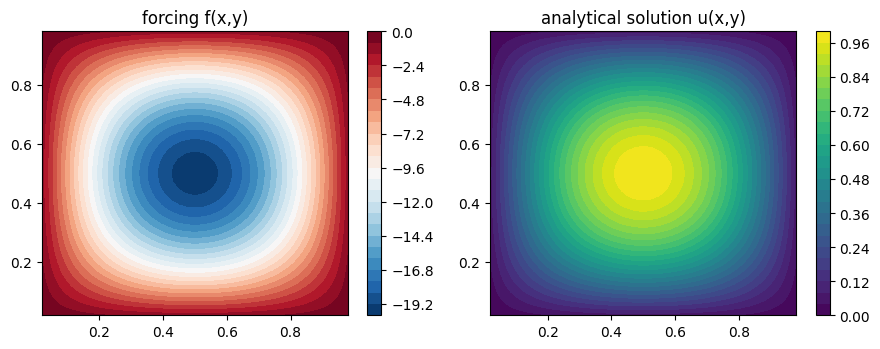

h = 0.01961   max|f| = 19.720   expected discretisation error ~ 3.16e-04


In [2]:
def grid_coords(n):
    h = 1.0 / (n + 1)
    x = np.linspace(h, 1 - h, n)
    X, Y = np.meshgrid(x, x)
    return h, X, Y

def make_standard(n=N):
    h, X, Y = grid_coords(n)
    U = np.sin(np.pi * X) * np.sin(np.pi * Y)
    F = -2 * np.pi**2 * U
    return h, X, Y, F, U

OTHER_MODES = [(a, b) for a in (1, 2, 3) for b in (1, 2, 3) if (a, b) != (1, 1)]

def make_varied_problem(n, rng):
    h, X, Y = grid_coords(n)
    modes, amps = [], []
    if rng.random() < 0.6:
        modes.append((1, 1)); amps.append(rng.uniform(0.5, 2.0) * rng.choice([-1, 1]))
    k_other = int(rng.integers(1, 4))
    for i in rng.choice(len(OTHER_MODES), size=k_other, replace=False):
        modes.append(OTHER_MODES[i]); amps.append(rng.uniform(0.1, 1.5) * rng.choice([-1, 1]))
    U = np.zeros((n, n)); F = np.zeros((n, n))
    for (a, b), c in zip(modes, amps):
        m = c * np.sin(a * np.pi * X) * np.sin(b * np.pi * Y)
        U += m; F += -(a**2 + b**2) * np.pi**2 * m
    return h, X, Y, F, U

h, X, Y, F_std, U_exact = make_standard(N)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
c0 = ax[0].contourf(X, Y, F_std, 30, cmap='RdBu_r'); ax[0].set_title('forcing f(x,y)'); plt.colorbar(c0, ax=ax[0])
c1 = ax[1].contourf(X, Y, U_exact, 30, cmap='viridis'); ax[1].set_title('analytical solution u(x,y)'); plt.colorbar(c1, ax=ax[1])
plt.tight_layout(); plt.show()
print(f'h = {h:.5f}   max|f| = {np.abs(F_std).max():.3f}   expected discretisation error ~ {np.pi**2*h**2/12:.2e}')

## 2. Solvers

All solvers use the same stopping rule: the **relative residual** $\max|Au-f| / \max|f|$ is evaluated every `SNAP_EVERY` = 10 iterations and
iteration stops when it is $\le$ `TOL`. This keeps the solver comparison fair.

- `gs_python`: textbook row-major Gauss-Seidel with Python loops (the naive baseline)
- `gs_numba_cpu`: the same algorithm compiled with Numba, single thread (the *fair* CPU baseline)
- `rb_solve`: Red-Black Gauss-Seidel. On CUDA: one thread per cell, red kernel then black kernel, residual kernel every 10 iterations
  (the per-cell residuals are reduced with a max on the host; the array is only 50x50). Falls back to NumPy when no GPU is present.
- `rb_solve(..., u_init=...)` supports a warm start, which is how the AI prediction is handed back to the solver.

In [3]:
def rel_residual(u, F, h):
    up = np.pad(u, 1)
    lap = (up[:-2, 1:-1] + up[2:, 1:-1] + up[1:-1, :-2] + up[1:-1, 2:] - 4.0 * u) / (h * h)
    return float(np.abs(lap - F).max() / np.abs(F).max())

# ---------------- CPU baselines
def gs_python(F, h, tol=TOL, max_iter=MAX_ITER, check_every=SNAP_EVERY):
    n = F.shape[0]; h2 = h * h
    up = np.zeros((n + 2, n + 2)); hist = [(0, 1.0)]
    t0 = time.perf_counter()
    for it in range(1, max_iter + 1):
        for i in range(1, n + 1):
            for j in range(1, n + 1):
                up[i, j] = 0.25 * (up[i-1, j] + up[i+1, j] + up[i, j-1] + up[i, j+1] - h2 * F[i-1, j-1])
        if it % check_every == 0:
            r = rel_residual(up[1:-1, 1:-1], F, h); hist.append((it, r))
            if r <= tol: break
    return dict(u=up[1:-1, 1:-1].copy(), iters=it, time=time.perf_counter() - t0, res=hist, converged=hist[-1][1] <= tol)

@numba.njit(cache=False)
def _gs_cpu_sweeps(up, F, h2, nsweeps):
    n = F.shape[0]
    for _ in range(nsweeps):
        for i in range(1, n + 1):
            for j in range(1, n + 1):
                up[i, j] = 0.25 * (up[i-1, j] + up[i+1, j] + up[i, j-1] + up[i, j+1] - h2 * F[i-1, j-1])

def gs_numba_cpu(F, h, tol=TOL, max_iter=MAX_ITER, check_every=SNAP_EVERY):
    n = F.shape[0]; up = np.zeros((n + 2, n + 2)); hist = [(0, 1.0)]
    t0 = time.perf_counter(); it = 0
    while it < max_iter:
        _gs_cpu_sweeps(up, F, h * h, check_every); it += check_every
        r = rel_residual(up[1:-1, 1:-1], F, h); hist.append((it, r))
        if r <= tol: break
    return dict(u=up[1:-1, 1:-1].copy(), iters=it, time=time.perf_counter() - t0, res=hist, converged=hist[-1][1] <= tol)

# ---------------- Red-Black GS (CUDA kernels + NumPy fallback)
if CUDA_OK:
    @cuda.jit
    def rb_sweep_kernel(u, F, h2, n, color):
        j, i = cuda.grid(2)                      # j = fastest-varying (column)
        if i >= n or j >= n:
            return
        if (i + j) % 2 != color:
            return
        s = 0.0
        if i > 0:     s += u[i-1, j]
        if i < n - 1: s += u[i+1, j]
        if j > 0:     s += u[i, j-1]
        if j < n - 1: s += u[i, j+1]
        u[i, j] = (s - h2 * F[i, j]) * 0.25

    @cuda.jit
    def residual_kernel(u, F, h2, n, out):
        j, i = cuda.grid(2)
        if i >= n or j >= n:
            return
        s = 0.0
        if i > 0:     s += u[i-1, j]
        if i < n - 1: s += u[i+1, j]
        if j > 0:     s += u[i, j-1]
        if j < n - 1: s += u[i, j+1]
        out[i, j] = abs((s - 4.0 * u[i, j]) / h2 - F[i, j])

def rb_solve(F_np, h, tol=TOL, max_iter=MAX_ITER, check_every=SNAP_EVERY, u_init=None,
             keep_snapshots=False, backend=None):
    backend = backend or ('cuda' if CUDA_OK else 'numpy')
    n = F_np.shape[0]; h2 = float(h * h)
    F64 = np.ascontiguousarray(F_np, dtype=np.float64); fmax = float(np.abs(F64).max())
    u0 = np.zeros((n, n)) if u_init is None else np.array(u_init, dtype=np.float64)
    r0 = rel_residual(u0, F64, h)
    hist = [(0, r0)]; snaps = [(0, u0.copy())] if keep_snapshots else []
    if r0 <= tol:
        return dict(u=u0, iters=0, time=0.0, res=hist, snaps=snaps, converged=True)
    it = 0; r = r0
    if backend == 'cuda':
        u_d = cuda.to_device(u0); F_d = cuda.to_device(F64); res_d = cuda.device_array((n, n), dtype=np.float64)
        tpb = (16, 16); blocks = (math.ceil(n / 16), math.ceil(n / 16))
        cuda.synchronize(); t0 = time.perf_counter()
        for it in range(1, max_iter + 1):
            rb_sweep_kernel[blocks, tpb](u_d, F_d, h2, n, 0)
            rb_sweep_kernel[blocks, tpb](u_d, F_d, h2, n, 1)
            if it % check_every == 0:
                residual_kernel[blocks, tpb](u_d, F_d, h2, n, res_d)
                r = float(res_d.copy_to_host().max()) / fmax; hist.append((it, r))
                if keep_snapshots: snaps.append((it, u_d.copy_to_host()))
                if r <= tol: break
        u = u_d.copy_to_host(); cuda.synchronize(); elapsed = time.perf_counter() - t0
    else:
        u = u0.copy(); I, J = np.indices((n, n)); masks = ((I + J) % 2 == 0, (I + J) % 2 == 1)
        t0 = time.perf_counter()
        for it in range(1, max_iter + 1):
            for m in masks:
                up = np.pad(u, 1)
                nb = up[:-2, 1:-1] + up[2:, 1:-1] + up[1:-1, :-2] + up[1:-1, 2:]
                u[m] = ((nb - h2 * F64) * 0.25)[m]
            if it % check_every == 0:
                r = rel_residual(u, F64, h); hist.append((it, r))
                if keep_snapshots: snaps.append((it, u.copy()))
                if r <= tol: break
        elapsed = time.perf_counter() - t0
    return dict(u=u, iters=it, time=elapsed, res=hist, snaps=snaps, converged=bool(r <= tol))

def timed(fn, reps=3):
    outs = [fn() for _ in range(reps)]
    ts = sorted(o['time'] for o in outs)
    return outs[-1], ts[len(ts) // 2]       # (last result, median time)

In [4]:
# ---- self test: CUDA kernels must agree with the NumPy reference (fails fast if something is wrong)
_h8, _, _, _F8, _ = make_standard(16)
_ref = rb_solve(_F8, _h8, tol=1e-30, max_iter=40, backend='numpy')
if CUDA_OK:
    _gpu = rb_solve(_F8, _h8, tol=1e-30, max_iter=40, backend='cuda')
    _d = np.abs(_gpu['u'] - _ref['u']).max()
    print(f'CUDA vs NumPy red-black after 40 iterations: max |diff| = {_d:.2e}')
    assert _d < 1e-10, 'CUDA kernel disagrees with the NumPy reference'
else:
    print('CUDA not available - skipped (NumPy backend in use).')

CUDA vs NumPy red-black after 40 iterations: max |diff| = 1.67e-16


## 3. Baselines on the standard problem (time to full convergence)

running pure-Python sequential GS ...
solver                        iters  time [s] final rel.res  max err vs analytical
Python GS (CPU)                3640   11.7009      9.99e-07              3.150e-04
Numba GS (CPU, 1 thread)       3640    0.0798      9.99e-07              3.150e-04
Red-Black GS (CUDA)            3830    0.4333      9.68e-07              3.155e-04

Red-Black vs pure Python :   27.0x
Red-Black vs Numba CPU   :   0.18x   (compiled CPU is faster at this grid size)
discretisation floor (CUDA solution vs analytical): 3.15e-04


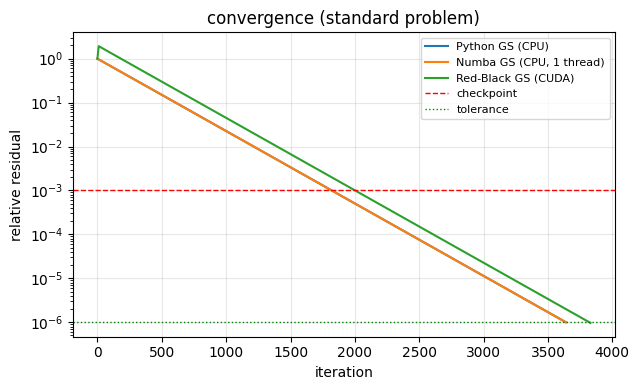

In [5]:
# warm-up: JIT-compile Numba CPU and CUDA code so compile time is not counted
_h, _, _, _F, _ = make_standard(16)
gs_numba_cpu(_F, _h, tol=1e-2); rb_solve(_F, _h, tol=1e-2)

BASE = {}
if RUN_PY_BASELINE:
    print('running pure-Python sequential GS ...')
    BASE['Python GS (CPU)'] = gs_python(F_std, h)
r_, _ = timed(lambda: gs_numba_cpu(F_std, h)); BASE['Numba GS (CPU, 1 thread)'] = r_; BASE['Numba GS (CPU, 1 thread)']['time'] = _
r_, _ = timed(lambda: rb_solve(F_std, h));      BASE['Red-Black GS (' + ('CUDA' if CUDA_OK else 'NumPy') + ')'] = r_; r_['time'] = _

# discrete reference solution = what the CUDA run converges to
U_disc = list(BASE.values())[-1]['u']
print(f"{'solver':28s} {'iters':>6s} {'time [s]':>9s} {'final rel.res':>13s} {'max err vs analytical':>22s}")
for k, v in BASE.items():
    print(f"{k:28s} {v['iters']:6d} {v['time']:9.4f} {v['res'][-1][1]:13.2e} {np.abs(v['u'] - U_exact).max():22.3e}")
t_py = BASE['Python GS (CPU)']['time'] if RUN_PY_BASELINE else None
t_nb = BASE['Numba GS (CPU, 1 thread)']['time']; t_rb = list(BASE.values())[-1]['time']
if t_py: print(f'\nRed-Black vs pure Python : {t_py / t_rb:6.1f}x')
print(f'Red-Black vs Numba CPU   : {t_nb / t_rb:6.2f}x   ({"GPU is faster" if t_rb < t_nb else "compiled CPU is faster at this grid size"})')
print(f'discretisation floor (CUDA solution vs analytical): {np.abs(U_disc - U_exact).max():.2e}')
RESULTS['baselines'] = {k: dict(iters=int(v['iters']), time=float(v['time']), err_vs_analytical=float(np.abs(v['u'] - U_exact).max())) for k, v in BASE.items()}

plt.figure(figsize=(6.5, 4))
for k, v in BASE.items():
    its_, rs_ = zip(*v['res']); plt.semilogy(its_, rs_, label=k)
plt.axhline(CHKPT_R, color='r', ls='--', lw=1, label='checkpoint'); plt.axhline(TOL, color='g', ls=':', lw=1, label='tolerance')
plt.xlabel('iteration'); plt.ylabel('relative residual'); plt.title('convergence (standard problem)'); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 3b. Where does the GPU actually help? (grid-size scaling)

At 50x50 there are only 2,500 unknowns, which is too little work to keep a GPU busy, so a compiled CPU loop can win.
This study times a fixed number of sweeps for increasing grid sizes (Numba CPU, 1 thread, vs CUDA red-black).

     N  CPU ms/sweep  GPU ms/sweep  GPU speedup
    50        0.0119        0.0829        0.14x
   100        0.0499        0.0862        0.58x
   200        0.2239        0.0906        2.47x
   400        0.9008        0.0840       10.72x
   800        3.4861        0.2246       15.52x
  1600       14.4440        0.8323       17.35x


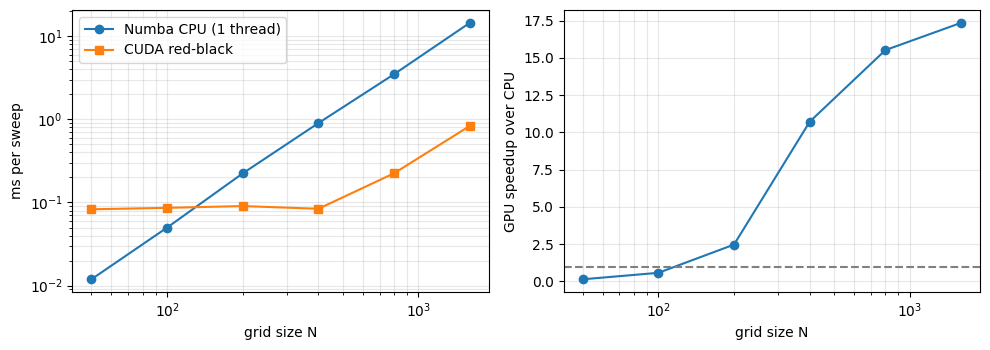

In [6]:
def bench_scaling(sizes=(50, 100, 200, 400, 800, 1600)):
    rows = []
    for n in sizes:
        h_ = 1.0 / (n + 1); F_ = np.ones((n, n)); nsw = int(np.clip(4e7 / (n * n), 20, 2000))
        up = np.zeros((n + 2, n + 2)); _gs_cpu_sweeps(up, F_, h_ * h_, 1)
        t0 = time.perf_counter(); _gs_cpu_sweeps(up, F_, h_ * h_, nsw); t_cpu = (time.perf_counter() - t0) / nsw
        u_d = cuda.to_device(np.zeros((n, n))); F_d = cuda.to_device(F_)
        tpb = (16, 16); blocks = (math.ceil(n / 16), math.ceil(n / 16))
        rb_sweep_kernel[blocks, tpb](u_d, F_d, h_ * h_, n, 0); cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(nsw):
            rb_sweep_kernel[blocks, tpb](u_d, F_d, h_ * h_, n, 0); rb_sweep_kernel[blocks, tpb](u_d, F_d, h_ * h_, n, 1)
        cuda.synchronize(); t_gpu = (time.perf_counter() - t0) / nsw
        rows.append((n, t_cpu * 1e3, t_gpu * 1e3, t_cpu / t_gpu))
    return rows

if CUDA_OK and QUICK == 0:
    rows = bench_scaling()
    print(f"{'N':>6s} {'CPU ms/sweep':>13s} {'GPU ms/sweep':>13s} {'GPU speedup':>12s}")
    for n, a, b, s in rows: print(f'{n:6d} {a:13.4f} {b:13.4f} {s:11.2f}x')
    RESULTS['scaling'] = [dict(N=n, cpu_ms=a, gpu_ms=b, speedup=s) for n, a, b, s in rows]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].loglog([r[0] for r in rows], [r[1] for r in rows], 'o-', label='Numba CPU (1 thread)')
    ax[0].loglog([r[0] for r in rows], [r[2] for r in rows], 's-', label='CUDA red-black')
    ax[0].set_xlabel('grid size N'); ax[0].set_ylabel('ms per sweep'); ax[0].legend(); ax[0].grid(alpha=.3, which='both')
    ax[1].semilogx([r[0] for r in rows], [r[3] for r in rows], 'o-'); ax[1].axhline(1, color='gray', ls='--')
    ax[1].set_xlabel('grid size N'); ax[1].set_ylabel('GPU speedup over CPU'); ax[1].grid(alpha=.3, which='both')
    plt.tight_layout(); plt.show()
else:
    print('scaling study skipped (needs a CUDA GPU and QUICK=0)')

## 4. Dataset: CUDA trajectories

For each random problem the red-black solver runs to `TOL`, saving the full grid every 10 iterations (plus the zero initial state).
* **Checkpoint** = first snapshot whose relative residual is $\le$ `CHKPT_R`. Everything before it is "HPC provided", everything after is what the AI must anticipate.
* **Scale** $s$ = max|u| of the checkpoint state. States are divided by $s$, which is available at hand-off time (no future information).
* Trajectories where the checkpoint comes before `SEQ_LEN` snapshots, or where fewer than 8 snapshots remain afterwards, are rejected.

generating 100 trajectories ...
  10/100 trajectories  (2 s)
  20/100 trajectories  (5 s)
  30/100 trajectories  (7 s)
  40/100 trajectories  (10 s)
  50/100 trajectories  (12 s)
  60/100 trajectories  (15 s)
  70/100 trajectories  (19 s)
  80/100 trajectories  (21 s)
  90/100 trajectories  (25 s)
  100/100 trajectories  (27 s)

accepted 100 of 100 problems | split train/val/test = 80/10/10
snapshots per trajectory: min 44, mean 220, max 377
checkpoint position (fraction of total iterations): mean 0.48, min 0.39, max 0.53


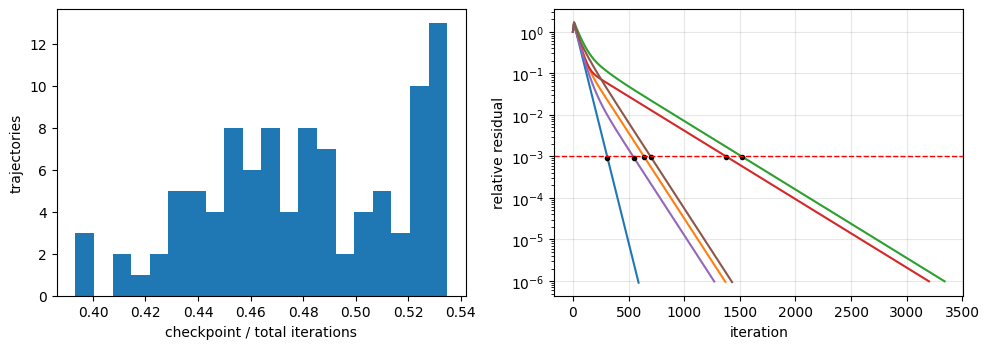

In [7]:
def build_trajectory(F, h, U_exact):
    r = rb_solve(F, h, tol=TOL, keep_snapshots=True)
    if not r['converged']: return None
    its = np.array([i for i, _ in r['snaps']]); res = np.array([x for _, x in r['res']])
    below = np.where(res <= CHKPT_R)[0]
    if len(below) == 0: return None
    k_ck = int(below[0]); T = len(its)
    if k_ck < SEQ_LEN + 1 or T - 1 - k_ck < 8: return None
    U = np.stack([u.reshape(-1) for _, u in r['snaps']])
    return dict(U=U, its=its, res=res, k_ck=k_ck, scale=float(np.abs(U[k_ck]).max()),
                F=F, h=h, U_exact=U_exact, n=F.shape[0])

def generate_dataset(n_traj, n=N):
    trajs, tries, t0 = [], 0, time.perf_counter()
    while len(trajs) < n_traj and tries < 6 * n_traj:
        rng = np.random.default_rng(100 + tries); tries += 1
        h_, _, _, F_, U_ = make_varied_problem(n, rng)
        tr = build_trajectory(F_, h_, U_)
        if tr is not None:
            trajs.append(tr)
            if len(trajs) % 10 == 0: print(f'  {len(trajs)}/{n_traj} trajectories  ({time.perf_counter() - t0:.0f} s)')
    return trajs, tries

print(f'generating {N_TRAJ} trajectories ...')
trajectories, n_tries = generate_dataset(N_TRAJ)
n_tr = int(0.8 * len(trajectories)); n_va = int(0.1 * len(trajectories))
train_trajs = trajectories[:n_tr]; val_trajs = trajectories[n_tr:n_tr + n_va]; test_trajs = trajectories[n_tr + n_va:]

frac = np.array([t['its'][t['k_ck']] / t['its'][-1] for t in trajectories])
T_all = np.array([len(t['its']) for t in trajectories]); K_all = np.array([t['k_ck'] for t in trajectories])
print(f'\naccepted {len(trajectories)} of {n_tries} problems | split train/val/test = {len(train_trajs)}/{len(val_trajs)}/{len(test_trajs)}')
print(f'snapshots per trajectory: min {T_all.min()}, mean {T_all.mean():.0f}, max {T_all.max()}')
print(f'checkpoint position (fraction of total iterations): mean {frac.mean():.2f}, min {frac.min():.2f}, max {frac.max():.2f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(frac, bins=20); ax[0].set_xlabel('checkpoint / total iterations'); ax[0].set_ylabel('trajectories')
for t in trajectories[:6]:
    ax[1].semilogy(t['its'], np.maximum(t['res'], 1e-12)); ax[1].plot(t['its'][t['k_ck']], t['res'][t['k_ck']], 'ko', ms=3)
ax[1].axhline(CHKPT_R, color='r', ls='--', lw=1); ax[1].set_xlabel('iteration'); ax[1].set_ylabel('relative residual'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
RESULTS['dataset'] = dict(n_traj=len(trajectories), ckpt_fraction_mean=float(frac.mean()), snapshots_mean=float(T_all.mean()))

### 4b. Features and targets

For a trajectory with normalised states $\hat u_t = u_t / s$ (snapshot $t$ = iteration $10t$), with $g(x) = \operatorname{asinh}(x / C)$:

| | definition |
|---|---|
| input token at $t$ | $[\,\hat u_t \;,\; g(\hat u_t - \hat u_{t-1})\,]$ (2 x N^2 numbers) |
| target "next" | $g(\hat u_{t+1} - \hat u_t)$: the next increment |
| target "final" | $g(\hat u_\infty - \hat u_t)$: remaining distance to the converged state |
| target "res" | $(\log_{10}$ relative residual$(t) + 3)/2$ (auxiliary) |

`asinh` is linear for small values and logarithmic for large ones, so a loss on it is roughly a *relative* error loss and the model is not blind to the tiny late-stage changes.
Predictions are inverted with $C\sinh(\cdot)$ and **added to the current state**.

In [8]:
def traj_features(tr):
    U = tr['U'] / tr['scale']; T = len(U); C = C_ASINH
    d_prev = np.zeros_like(U); d_prev[1:] = U[1:] - U[:-1]
    d_next = np.zeros_like(U); d_next[:-1] = U[1:] - U[:-1]
    valid = np.ones(T); valid[-1] = 0.0
    return dict(state=U, din=np.arcsinh(d_prev / C), ynext=np.arcsinh(d_next / C), yfin=np.arcsinh((U[-1][None] - U) / C),
                yres=(np.log10(np.maximum(tr['res'], 1e-12)) + 3.0) / 2.0, valid=valid,
                post=(np.arange(T) >= tr['k_ck']).astype(np.float64), its=tr['its'])

class Packed:
    # all windows of a set of trajectories, kept on the compute device
    def __init__(self, trajs):
        parts = [traj_features(t) for t in trajs]
        cat = lambda k, dt=np.float32: torch.tensor(np.concatenate([p[k] for p in parts]).astype(dt), device=DEVICE)
        self.state, self.din, self.ynext, self.yfin = cat('state'), cat('din'), cat('ynext'), cat('yfin')
        self.yres, self.valid, self.post, self.its = cat('yres'), cat('valid'), cat('post'), cat('its', np.int64)
        starts, off = [], 0
        for p in parts:
            T = len(p['its']); starts += list(range(off, off + T - SEQ_LEN + 1)); off += T
        self.starts = torch.tensor(starts, device=DEVICE)
        self.ar = torch.arange(SEQ_LEN, device=DEVICE)[None]
    def batch(self, s):
        idx = s[:, None] + self.ar
        return (torch.cat([self.state[idx], self.din[idx]], -1), self.its[idx], self.ynext[idx], self.yfin[idx],
                self.yres[idx], self.valid[idx], self.post[idx])

pk_train, pk_val = Packed(train_trajs), Packed(val_trajs)
print(f'windows: train {len(pk_train.starts)}, val {len(pk_val.starts)}  | input dim per token {2 * N * N}')

windows: train 16392, val 2709  | input dim per token 5000


## 5. Model: decoder-only Transformer

* Token = one saved iteration state: `Linear(2N^2 -> d_model)` + LayerNorm.
* Positional signal = sinusoids of $\log(1+\text{iteration})$ (actual iteration number, log-scaled).
* 4 pre-LN decoder blocks, 4 heads, causal mask, GELU feed-forward, dropout 0.1.
* Three heads on every position: **next increment**, **jump to final state**, **log-residual** (auxiliary).

In [9]:
class LogIterEncoding(nn.Module):
    def __init__(self, d, w_min=0.25, w_max=32.0):
        super().__init__()
        self.register_buffer('w', torch.exp(torch.linspace(math.log(w_min), math.log(w_max), d // 2)))
    def forward(self, it):
        a = torch.log1p(it.float()).unsqueeze(-1) * self.w
        return torch.cat([a.sin(), a.cos()], -1)

class Block(nn.Module):
    def __init__(self, d, heads, d_ff, p):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, d_ff), nn.GELU(), nn.Dropout(p), nn.Linear(d_ff, d))
        self.drop = nn.Dropout(p)
    def forward(self, x, mask):
        h = self.ln1(x)
        a, _ = self.attn(h, h, h, attn_mask=mask, need_weights=False)
        x = x + self.drop(a)
        return x + self.drop(self.ff(self.ln2(x)))

class PoissonTransformer(nn.Module):
    def __init__(self, grid, d_model, heads, layers, d_ff, p):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(2 * grid, d_model), nn.LayerNorm(d_model))
        self.pos = LogIterEncoding(d_model)
        self.drop = nn.Dropout(p)
        self.blocks = nn.ModuleList([Block(d_model, heads, d_ff, p) for _ in range(layers)])
        self.norm = nn.LayerNorm(d_model)
        self.head_next, self.head_final, self.head_res = nn.Linear(d_model, grid), nn.Linear(d_model, grid), nn.Linear(d_model, 1)
        for hd in (self.head_next, self.head_final, self.head_res):
            nn.init.normal_(hd.weight, std=0.01); nn.init.zeros_(hd.bias)
    def forward(self, x, it):
        B, T, _ = x.shape
        h = self.drop(self.inp(x) + self.pos(it))
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), 1)   # True = may not attend (future)
        for b in self.blocks: h = b(h, mask)
        h = self.norm(h)
        return self.head_next(h), self.head_final(h), self.head_res(h)

model = PoissonTransformer(N * N, D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT).to(DEVICE)
print(f'parameters: {sum(p.numel() for p in model.parameters()):,}')

parameters: 4,674,953


## 6. Training (teacher forcing, AdamW, warm-up + cosine decay, early stopping on validation loss)

epoch |    train |      val (next / final / res) | lr
    1 |   3.2302 |   0.9425 (0.371 / 0.555 / 0.160) | 3.3e-04
    5 |   0.3166 |   0.2928 (0.110 / 0.180 / 0.023) | 5.0e-04
   10 |   0.1745 |   0.2204 (0.071 / 0.146 / 0.026) | 4.9e-04
   15 |   0.1322 |   0.2223 (0.063 / 0.158 / 0.016) | 4.7e-04
   20 |   0.1029 |   0.2047 (0.057 / 0.146 / 0.016) | 4.5e-04
   25 |   0.0919 |   0.2139 (0.063 / 0.150 / 0.016) | 4.3e-04
   30 |   0.0743 |   0.2174 (0.057 / 0.159 / 0.014) | 4.0e-04
   35 |   0.0665 |   0.2128 (0.057 / 0.155 / 0.012) | 3.7e-04
early stop at epoch 36 (best epoch 16)

training time 150 s | best epoch 16 | best val loss 0.1928


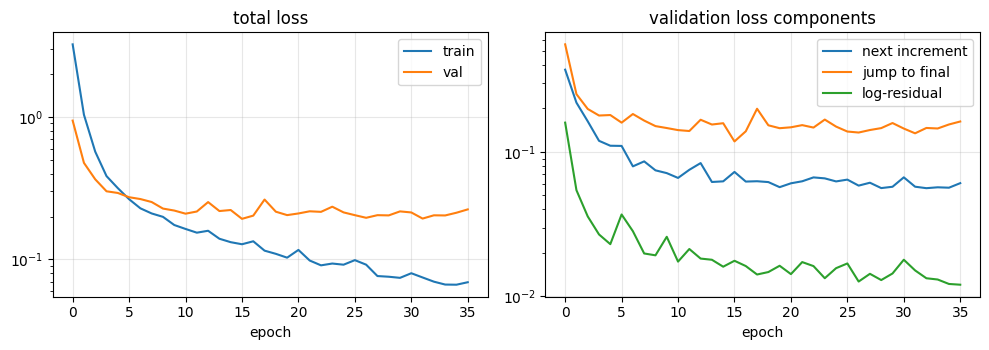

In [10]:
def run_epoch(pk, train, opt=None):
    model.train(train)
    order = pk.starts[torch.randperm(len(pk.starts), device=DEVICE)] if train else pk.starts
    acc, wsum = np.zeros(4), 0
    for b in range(0, len(order), BATCH):
        x, it, yn, yf, yr, valid, post = pk.batch(order[b:b + BATCH])
        with torch.set_grad_enabled(train):
            pn, pf, pr = model(x, it)
            w = W_PRE + (1.0 - W_PRE) * post
            ln = (((pn - yn) ** 2).mean(-1) * valid * w).sum() / (valid * w).sum()
            lf = (((pf - yf) ** 2).mean(-1) * w).sum() / w.sum()
            lr = (((pr.squeeze(-1) - yr) ** 2) * w).sum() / w.sum()
            loss = W_NEXT * ln + W_FINAL * lf + W_RES * lr
        if train:
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        k = len(x); acc += k * np.array([loss.item(), ln.item(), lf.item(), lr.item()]); wsum += k
    return acc / wsum

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: min(1.0, (e + 1) / WARMUP_EPOCHS) *
                                          (0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(1.0, e / EPOCHS)))))
hist_tr, hist_va = [], []; best, best_state, bad = 1e30, None, 0
t_start = time.perf_counter()
print(f"{'epoch':>5s} | {'train':>8s} | {'val':>8s} (next / final / res) | lr")
for ep in range(1, EPOCHS + 1):
    tr_l = run_epoch(pk_train, True, opt)
    with torch.no_grad(): va_l = run_epoch(pk_val, False)
    sched.step(); hist_tr.append(tr_l); hist_va.append(va_l)
    if va_l[0] < best - 1e-6:
        best, bad = va_l[0], 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}; best_ep = ep
    else:
        bad += 1
    if ep == 1 or ep % 5 == 0 or bad == 0 and ep > EPOCHS - 3:
        print(f'{ep:5d} | {tr_l[0]:8.4f} | {va_l[0]:8.4f} ({va_l[1]:.3f} / {va_l[2]:.3f} / {va_l[3]:.3f}) | {sched.get_last_lr()[0]:.1e}')
    if bad >= PATIENCE:
        print(f'early stop at epoch {ep} (best epoch {best_ep})'); break
t_train = time.perf_counter() - t_start
model.load_state_dict(best_state); model.eval()
print(f'\ntraining time {t_train:.0f} s | best epoch {best_ep} | best val loss {best:.4f}')
RESULTS['training'] = dict(time_s=t_train, best_epoch=int(best_ep), best_val_loss=float(best), epochs_run=len(hist_tr))
torch.save(best_state, os.path.join(OUT_DIR, 'poisson_transformer.pt'))

hv, ht = np.array(hist_va), np.array(hist_tr)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].semilogy(ht[:, 0], label='train'); ax[0].semilogy(hv[:, 0], label='val'); ax[0].set_xlabel('epoch'); ax[0].set_title('total loss'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].semilogy(hv[:, 1], label='next increment'); ax[1].semilogy(hv[:, 2], label='jump to final'); ax[1].semilogy(hv[:, 3], label='log-residual')
ax[1].set_xlabel('epoch'); ax[1].set_title('validation loss components'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Inference from the checkpoint

Given the last `SEQ_LEN` + 1 saved states up to the checkpoint, the model gives two kinds of prediction:
* **Jump:** $\hat u_\infty = \hat u_{ck} + C\sinh(\text{final head})$, a single forward pass.
* **Rollout:** repeatedly add the predicted increment, append the new state to the context and continue (autoregressive; errors can accumulate).

Baselines (no learning):
* **Freeze:** assume the checkpoint state is already the answer.
* **Aitken-style extrapolation:** $\hat u_\infty = u_{ck} + \Delta\,\rho/(1-\rho)$ with $\Delta = u_{ck}-u_{ck-1}$ and one scalar $\rho = \langle\Delta_t,\Delta_{t-1}\rangle/\langle\Delta_{t-1},\Delta_{t-1}\rangle$ estimated from the last two increments.

All errors are RMSE on states divided by the scale $s$, so 1e-3 means 0.1% of the solution amplitude.

In [11]:
def inv(y): return C_ASINH * np.sinh(np.clip(y, -CLAMP, CLAMP))
def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))

@torch.no_grad()
def model_step(states, its):
    # states: (L+1, G) normalised, its: (L+1,). Returns increment, jump, log10-residual estimate for the LAST state.
    d = states[1:] - states[:-1]
    x = np.concatenate([states[1:], np.arcsinh(d / C_ASINH)], -1).astype(np.float32)
    pn, pf, pr = model(torch.from_numpy(x)[None].to(DEVICE), torch.from_numpy(np.asarray(its[1:], dtype=np.int64))[None].to(DEVICE))
    return (inv(pn[0, -1].double().cpu().numpy()), inv(pf[0, -1].double().cpu().numpy()), float(pr[0, -1, 0]) * 2.0 - 3.0)

def predict_from_checkpoint(tr, n_steps):
    U = tr['U'] / tr['scale']; k0 = tr['k_ck']; L = SEQ_LEN
    hist, its = list(U[k0 - L:k0 + 1]), list(tr['its'][k0 - L:k0 + 1])
    jump, roll, res_head = None, [], []
    for s in range(n_steps):
        inc, fin, lr = model_step(np.stack(hist[-(L + 1):]), np.array(its[-(L + 1):]))
        if s == 0: jump = hist[-1] + fin
        hist.append(hist[-1] + inc); its.append(its[-1] + SNAP_EVERY); roll.append(hist[-1]); res_head.append(lr)
    return dict(jump=jump, roll=np.stack(roll), res_head=np.array(res_head))

def aitken_jump(U, k0):
    d1, d0 = U[k0] - U[k0 - 1], U[k0 - 1] - U[k0 - 2]
    rho = float(np.clip(d1 @ d0 / (d0 @ d0 + 1e-300), 0.0, 0.9999))
    return U[k0] + d1 * rho / (1.0 - rho)

def evaluate(tr):
    U = tr['U'] / tr['scale']; k0 = tr['k_ck']; n_steps = len(U) - 1 - k0; ustar = U[-1]
    P = predict_from_checkpoint(tr, n_steps); A = aitken_jump(U, k0)
    return dict(P=P, aitken=A, jump_ai=rmse(P['jump'], ustar), jump_freeze=rmse(U[k0], ustar), jump_aitken=rmse(A, ustar),
                roll_ai=np.array([rmse(P['roll'][j], U[k0 + 1 + j]) for j in range(n_steps)]),
                roll_freeze=np.array([rmse(U[k0], U[k0 + 1 + j]) for j in range(n_steps)]))
print('inference functions ready')

inference functions ready


## 8. Evaluation on held-out test trajectories (never seen in training or validation)

 #  ckpt it | jump: freeze     Aitken         AI | rollout mean: freeze         AI
 0     1180 |     1.23e-03   1.57e-06   3.98e-04 |             1.05e-03   5.99e-03
 1      310 |     2.39e-04   2.34e-07   9.39e-05 |             2.09e-04   4.86e-04
 2      310 |     2.39e-04   2.34e-07   6.89e-05 |             2.09e-04   1.62e-04
 3     1450 |     6.51e-04   7.77e-07   4.77e-04 |             5.60e-04   1.12e-02
 4      310 |     2.39e-04   2.34e-07   9.39e-05 |             2.09e-04   4.86e-04
 5     1260 |     1.26e-03   2.73e-06   4.93e-04 |             1.08e-03   9.08e-03
 6      810 |     2.32e-04   2.49e-07   6.16e-05 |             2.00e-04   1.59e-04
 7      260 |     2.29e-04   2.14e-05   8.64e-05 |             2.00e-04   6.12e-04
 8      700 |     4.69e-04   4.57e-07   2.79e-04 |             4.05e-04   6.72e-04
 9      500 |     6.67e-04   5.64e-05   4.83e-04 |             5.75e-04   4.75e-03

JUMP    error ratio AI / freeze  (geo-mean, <1 is better): 0.422   AI beats freeze on 

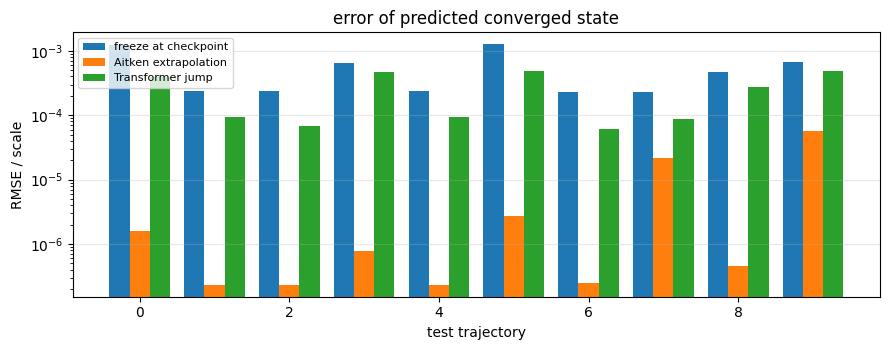


iterations still needed to reach TOL (mean over test set): continue from checkpoint 874 | restart from Aitken 85 | restart from AI jump 999


In [12]:
test_ev = [evaluate(t) for t in test_trajs]
print(f"{'#':>2s} {'ckpt it':>8s} | {'jump: freeze':>12s} {'Aitken':>10s} {'AI':>10s} | {'rollout mean: freeze':>20s} {'AI':>10s}")
for i, (t, e) in enumerate(zip(test_trajs, test_ev)):
    print(f"{i:2d} {t['its'][t['k_ck']]:8d} | {e['jump_freeze']:12.2e} {e['jump_aitken']:10.2e} {e['jump_ai']:10.2e} | {e['roll_freeze'].mean():20.2e} {e['roll_ai'].mean():10.2e}")

jf = np.array([e['jump_freeze'] for e in test_ev]); ja = np.array([e['jump_aitken'] for e in test_ev]); jm = np.array([e['jump_ai'] for e in test_ev])
rf = np.array([e['roll_freeze'].mean() for e in test_ev]); rm = np.array([e['roll_ai'].mean() for e in test_ev])
gm = lambda a, b: float(np.exp(np.mean(np.log(a / b))))
print(f'\nJUMP    error ratio AI / freeze  (geo-mean, <1 is better): {gm(jm, jf):.3f}   AI beats freeze on {(jm < jf).sum()}/{len(jm)}')
print(f'JUMP    error ratio AI / Aitken  (geo-mean, <1 is better): {gm(jm, ja):.3f}   AI beats Aitken on {(jm < ja).sum()}/{len(jm)}')
print(f'ROLLOUT error ratio AI / freeze  (geo-mean, <1 is better): {gm(rm, rf):.3f}   AI beats freeze on {(rm < rf).sum()}/{len(rm)}')
RESULTS['test'] = dict(jump_ratio_vs_freeze=gm(jm, jf), jump_ratio_vs_aitken=gm(jm, ja), rollout_ratio_vs_freeze=gm(rm, rf),
                       jump_ai_median=float(np.median(jm)), jump_freeze_median=float(np.median(jf)), jump_aitken_median=float(np.median(ja)))

x = np.arange(len(test_ev)); w = 0.27
plt.figure(figsize=(9, 3.6))
plt.bar(x - w, jf, w, label='freeze at checkpoint'); plt.bar(x, ja, w, label='Aitken extrapolation'); plt.bar(x + w, jm, w, label='Transformer jump')
plt.yscale('log'); plt.xlabel('test trajectory'); plt.ylabel('RMSE / scale'); plt.title('error of predicted converged state'); plt.legend(fontsize=8); plt.grid(alpha=.3, axis='y')
plt.tight_layout(); plt.show()

# how many solver iterations are still needed when the solve is restarted from each prediction?
def iters_from(tr, u_norm): return rb_solve(tr['F'], tr['h'], tol=TOL, u_init=u_norm.reshape(tr['n'], tr['n']) * tr['scale'])['iters']
it_cont = [iters_from(t, t['U'][t['k_ck']] / t['scale']) for t in test_trajs]
it_ai   = [iters_from(t, e['P']['jump']) for t, e in zip(test_trajs, test_ev)]
it_ait  = [iters_from(t, e['aitken']) for t, e in zip(test_trajs, test_ev)]
print(f'\niterations still needed to reach TOL (mean over test set): continue from checkpoint {np.mean(it_cont):.0f} | '
      f'restart from Aitken {np.mean(it_ait):.0f} | restart from AI jump {np.mean(it_ai):.0f}')
RESULTS['test']['iters_after_ckpt'] = dict(continue_=float(np.mean(it_cont)), aitken=float(np.mean(it_ait)), ai=float(np.mean(it_ai)))

### 8b. Sensitivity to the hand-off point

The same trained model, evaluated when the HPC phase is stopped at different relative residuals (scale $s$ is taken from the state at that hand-off).
This shows *where* a learned jump is competitive with a classical extrapolation: the earlier the hand-off, the more modes are still active and the less a single-rate extrapolation can capture.
(Training used the `CHKPT_R` hand-off only to define the scale and to weight positions; all positions of every training trajectory were seen.)

 hand-off residual   n |     freeze     Aitken  Transformer | AI/freeze AI/Aitken   (median RMSE/scale)
             1e-01   5 |   5.26e-02   1.73e-02     2.22e-02 |     0.422       1.3
             3e-02   9 |   1.30e-02   1.02e-04     3.88e-03 |     0.299      38.1
             1e-02  10 |   3.56e-03   6.68e-05     1.88e-03 |     0.527      28.1
             3e-03  10 |   1.10e-03   3.63e-06     6.09e-04 |     0.554     167.5
             1e-03  10 |   3.54e-04   6.17e-07     1.87e-04 |     0.527     302.5
             3e-04  10 |   1.05e-04   5.54e-07     2.97e-05 |     0.282      53.6
             1e-04  10 |   3.58e-05   5.53e-07     1.19e-05 |     0.332      21.4


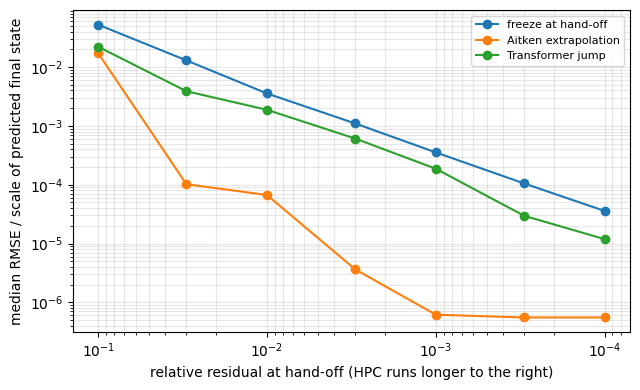

In [13]:
def jump_errors(tr, k0):
    U = tr['U']; sc = np.abs(U[k0]).max(); Un = U / sc; ustar = Un[-1]; L = SEQ_LEN
    _, fin, _ = model_step(Un[k0 - L:k0 + 1], tr['its'][k0 - L:k0 + 1])
    return rmse(Un[k0], ustar), rmse(aitken_jump(Un, k0), ustar), rmse(Un[k0] + fin, ustar)

levels = [1e-1, 3e-2, 1e-2, 3e-3, 1e-3, 3e-4, 1e-4]
sweep = []
for lv in levels:
    rows = []
    for t in test_trajs:
        idx = np.where(t['res'] <= lv)[0]
        if len(idx) == 0: continue
        k0 = int(idx[0])
        if k0 < SEQ_LEN + 1 or len(t['its']) - 1 - k0 < 1: continue
        rows.append(jump_errors(t, k0))
    if rows: sweep.append((lv, len(rows)) + tuple(np.median(np.array(rows), axis=0)))
print(f"{'hand-off residual':>18s} {'n':>3s} | {'freeze':>10s} {'Aitken':>10s} {'Transformer':>12s} | {'AI/freeze':>9s} {'AI/Aitken':>9s}   (median RMSE/scale)")
for lv, n_, a, b, c in sweep: print(f'{lv:18.0e} {n_:3d} | {a:10.2e} {b:10.2e} {c:12.2e} | {c / a:9.3f} {c / b:9.1f}')
RESULTS['handoff_sweep'] = [dict(residual=lv, n=n_, freeze=a, aitken=b, ai=c) for lv, n_, a, b, c in sweep]
plt.figure(figsize=(6.5, 4))
for j, nm in enumerate(['freeze at hand-off', 'Aitken extrapolation', 'Transformer jump']):
    plt.loglog([r[0] for r in sweep], [r[2 + j] for r in sweep], 'o-', label=nm)
plt.gca().invert_xaxis(); plt.xlabel('relative residual at hand-off (HPC runs longer to the right)'); plt.ylabel('median RMSE / scale of predicted final state')
plt.legend(fontsize=8); plt.grid(alpha=.3, which='both'); plt.tight_layout(); plt.show()

## 9. Standard problem: sin(pi x) sin(pi y) (a case the model has never seen)

checkpoint at iteration 2010 of 3830  (52% of the solve); remaining 1820 iterations
JUMP error (RMSE/scale):  freeze 2.48e-04 | Aitken 2.47e-07 | Transformer 1.08e-05
ROLLOUT mean error:       freeze 2.13e-04 | Transformer 2.52e-04  (final step: 4.73e-04)
  max |u - analytical|, freeze                  : 1.694e-04
  max |u - analytical|, Aitken                  : 3.160e-04
  max |u - analytical|, Transformer jump        : 3.611e-04
  max |u - analytical|, Transformer rollout end : 1.272e-03
  max |u - analytical|, CUDA converged          : 3.155e-04


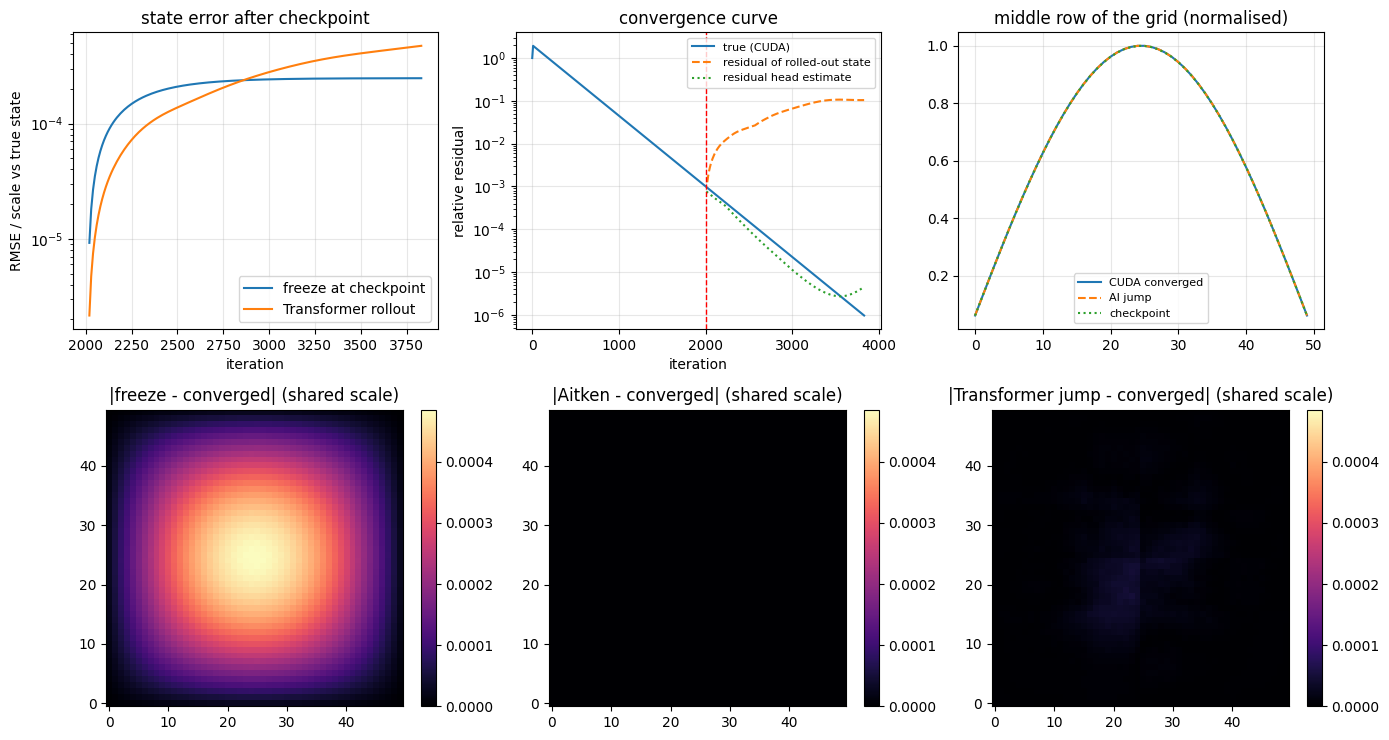

In [14]:
tr_std = build_trajectory(F_std, h, U_exact)
assert tr_std is not None, 'standard trajectory rejected (checkpoint too early?)'
ev = evaluate(tr_std); P = ev['P']
U = tr_std['U'] / tr_std['scale']; k0 = tr_std['k_ck']; its = tr_std['its']; s = tr_std['scale']
print(f"checkpoint at iteration {its[k0]} of {its[-1]}  ({its[k0] / its[-1]:.0%} of the solve); remaining {its[-1] - its[k0]} iterations")
print(f"JUMP error (RMSE/scale):  freeze {ev['jump_freeze']:.2e} | Aitken {ev['jump_aitken']:.2e} | Transformer {ev['jump_ai']:.2e}")
print(f"ROLLOUT mean error:       freeze {ev['roll_freeze'].mean():.2e} | Transformer {ev['roll_ai'].mean():.2e}  (final step: {ev['roll_ai'][-1]:.2e})")
for name, u in [('freeze', U[k0]), ('Aitken', ev['aitken']), ('Transformer jump', P['jump']), ('Transformer rollout end', P['roll'][-1]), ('CUDA converged', U[-1])]:
    print(f"  max |u - analytical|, {name:24s}: {np.abs(u.reshape(N, N) * s - U_exact).max():.3e}")
RESULTS['standard'] = dict(ckpt_iter=int(its[k0]), total_iter=int(its[-1]), jump_ai=ev['jump_ai'], jump_freeze=ev['jump_freeze'], jump_aitken=ev['jump_aitken'],
                           rollout_ai_mean=float(ev['roll_ai'].mean()), rollout_freeze_mean=float(ev['roll_freeze'].mean()),
                           err_vs_analytical_jump=float(np.abs(P['jump'].reshape(N, N) * s - U_exact).max()))

post_its = its[k0 + 1:]
res_roll = np.array([rel_residual(r.reshape(N, N) * s, F_std, h) for r in P['roll']])
fig, ax = plt.subplots(2, 3, figsize=(14, 7.5))
ax[0, 0].semilogy(post_its, ev['roll_freeze'], label='freeze at checkpoint'); ax[0, 0].semilogy(post_its, ev['roll_ai'], label='Transformer rollout')
ax[0, 0].set_xlabel('iteration'); ax[0, 0].set_ylabel('RMSE / scale vs true state'); ax[0, 0].set_title('state error after checkpoint'); ax[0, 0].legend(); ax[0, 0].grid(alpha=.3)
ax[0, 1].semilogy(its, tr_std['res'], label='true (CUDA)'); ax[0, 1].semilogy(post_its, res_roll, '--', label='residual of rolled-out state')
ax[0, 1].semilogy(its[k0:k0 + len(P['res_head'])], 10 ** P['res_head'], ':', label='residual head estimate')
ax[0, 1].axvline(its[k0], color='r', ls='--', lw=1); ax[0, 1].set_xlabel('iteration'); ax[0, 1].set_ylabel('relative residual'); ax[0, 1].set_title('convergence curve'); ax[0, 1].legend(fontsize=8); ax[0, 1].grid(alpha=.3)
ax[0, 2].plot(U[-1].reshape(N, N)[N // 2], label='CUDA converged'); ax[0, 2].plot(P['jump'].reshape(N, N)[N // 2], '--', label='AI jump'); ax[0, 2].plot(U[k0].reshape(N, N)[N // 2], ':', label='checkpoint')
ax[0, 2].set_title('middle row of the grid (normalised)'); ax[0, 2].legend(fontsize=8); ax[0, 2].grid(alpha=.3)
maps = [('freeze', U[k0]), ('Aitken', ev['aitken']), ('Transformer jump', P['jump'])]
vmax = max(np.abs(m - U[-1]).max() for _, m in maps)
for a, (nm, m) in zip(ax[1], maps):
    im = a.imshow(np.abs(m - U[-1]).reshape(N, N), origin='lower', cmap='magma', vmin=0, vmax=vmax)
    a.set_title(f'|{nm} - converged| (shared scale)'); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'standard_problem.png'), dpi=130); plt.show()

## 10. Hybrid timing (measured)

* **Full CUDA:** solve from zero to `TOL`.
* **Hybrid:** CUDA to the checkpoint (with snapshots saved, since the model needs the history) + Transformer jump + CUDA warm-start from the jump until `TOL`.

Both end at the same tolerance, so the comparison is equal-accuracy. Each timing is the median of 3 runs after JIT warm-up. Times for the AI include moving data to and from the GPU.

In [15]:
def hybrid_timing(tr, reps=3):
    F_, h_, s_ = tr['F'], tr['h'], tr['scale']; n_ = tr['n']
    full, t_full = timed(lambda: rb_solve(F_, h_, tol=TOL), reps)
    ck, t_ck = timed(lambda: rb_solve(F_, h_, tol=CHKPT_R, keep_snapshots=True), reps)
    cont, t_cont = timed(lambda: rb_solve(F_, h_, tol=TOL, u_init=ck['u']), reps)
    hist_states = np.stack([u.reshape(-1) for _, u in ck['snaps'][-(SEQ_LEN + 1):]]) / s_
    hist_its = np.array([i for i, _ in ck['snaps'][-(SEQ_LEN + 1):]])
    ts = []
    for _ in range(reps + 2):
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        t0 = time.perf_counter(); _, fin, _ = model_step(hist_states, hist_its); u_jump = (hist_states[-1] + fin).reshape(n_, n_) * s_
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        ts.append(time.perf_counter() - t0)
    t_ai = float(np.median(ts))
    warm, t_warm = timed(lambda: rb_solve(F_, h_, tol=TOL, u_init=u_jump), reps)
    return dict(t_full=t_full, it_full=full['iters'], t_ck=t_ck, it_ck=ck['iters'], t_cont=t_cont, it_cont=cont['iters'],
                t_ai=t_ai, t_warm=t_warm, it_warm=warm['iters'], t_hybrid=t_ck + t_ai + t_warm, u_warm=warm['u'], u_full=full['u'])

H = hybrid_timing(tr_std)
print(f"{'strategy':44s} {'iterations':>10s} {'time [s]':>9s}")
print(f"{'full CUDA solve (zero -> TOL)':44s} {H['it_full']:10d} {H['t_full']:9.4f}")
print(f"{'  CUDA to checkpoint (snapshots saved)':44s} {H['it_ck']:10d} {H['t_ck']:9.4f}")
print(f"{'  + finish from checkpoint (no AI)':44s} {H['it_cont']:10d} {H['t_cont']:9.4f}")
print(f"{'  + Transformer jump (inference)':44s} {'-':>10s} {H['t_ai']:9.4f}")
print(f"{'  + CUDA warm-start from AI jump to TOL':44s} {H['it_warm']:10d} {H['t_warm']:9.4f}")
print(f"{'hybrid total (ckpt + AI + warm-start)':44s} {H['it_ck'] + H['it_warm']:10d} {H['t_hybrid']:9.4f}")
print(f"\nhybrid vs full CUDA: {H['t_full'] / H['t_hybrid']:.2f}x   | iterations saved after checkpoint: {H['it_cont'] - H['it_warm']} of {H['it_cont']}")
print(f"final max error vs analytical: full CUDA {np.abs(H['u_full'] - U_exact).max():.3e} | hybrid {np.abs(H['u_warm'] - U_exact).max():.3e}")
RESULTS['hybrid'] = {k: (float(v) if not isinstance(v, np.ndarray) else None) for k, v in H.items() if not isinstance(v, np.ndarray)}

strategy                                     iterations  time [s]
full CUDA solve (zero -> TOL)                      3830    0.4286
  CUDA to checkpoint (snapshots saved)             2010    0.2293
  + finish from checkpoint (no AI)                 1820    0.2080
  + Transformer jump (inference)                      -    0.0038
  + CUDA warm-start from AI jump to TOL             880    0.0987
hybrid total (ckpt + AI + warm-start)              2890    0.3318

hybrid vs full CUDA: 1.29x   | iterations saved after checkpoint: 940 of 1820
final max error vs analytical: full CUDA 3.155e-04 | hybrid 3.165e-04


## 11. Summary

In [16]:
print('=' * 70); print('SUMMARY'); print('=' * 70)
b = RESULTS['baselines']
for k, v in b.items(): print(f"{k:28s} {v['iters']:6d} it  {v['time']:8.3f} s   err vs analytical {v['err_vs_analytical']:.2e}")
print(f"\ntraining: {RESULTS['training']['time_s']:.0f} s, best epoch {RESULTS['training']['best_epoch']}, best val loss {RESULTS['training']['best_val_loss']:.4f}")
t = RESULTS['test']
print(f"\nTEST SET (jump error vs converged CUDA state, RMSE/scale, median over {len(test_trajs)} trajectories):")
print(f"  freeze {t['jump_freeze_median']:.2e} | Aitken {t['jump_aitken_median']:.2e} | Transformer {t['jump_ai_median']:.2e}")
print(f"  geo-mean ratio AI/freeze {t['jump_ratio_vs_freeze']:.3f}, AI/Aitken {t['jump_ratio_vs_aitken']:.3f}, rollout AI/freeze {t['rollout_ratio_vs_freeze']:.3f}")
print(f"  iterations to TOL after checkpoint: continue {t['iters_after_ckpt']['continue_']:.0f} | from AI jump {t['iters_after_ckpt']['ai']:.0f} | from Aitken {t['iters_after_ckpt']['aitken']:.0f}")
sd = RESULTS['standard']; hy = RESULTS['hybrid']
print(f"\nSTANDARD PROBLEM: jump error freeze {sd['jump_freeze']:.2e} | Aitken {sd['jump_aitken']:.2e} | Transformer {sd['jump_ai']:.2e}")
print(f"HYBRID: {hy['t_hybrid']:.3f} s vs full CUDA {hy['t_full']:.3f} s  ({hy['t_full'] / hy['t_hybrid']:.2f}x)")
with open(os.path.join(OUT_DIR, 'results.json'), 'w') as f: json.dump(RESULTS, f, indent=2, default=float)
print(f"\nsaved: {os.path.join(OUT_DIR, 'results.json')}, poisson_transformer.pt, standard_problem.png")

SUMMARY
Python GS (CPU)                3640 it    11.701 s   err vs analytical 3.15e-04
Numba GS (CPU, 1 thread)       3640 it     0.080 s   err vs analytical 3.15e-04
Red-Black GS (CUDA)            3830 it     0.433 s   err vs analytical 3.15e-04

training: 150 s, best epoch 16, best val loss 0.1928

TEST SET (jump error vs converged CUDA state, RMSE/scale, median over 10 trajectories):
  freeze 3.54e-04 | Aitken 6.17e-07 | Transformer 1.87e-04
  geo-mean ratio AI/freeze 0.422, AI/Aitken 152.900, rollout AI/freeze 3.256
  iterations to TOL after checkpoint: continue 874 | from AI jump 999 | from Aitken 85

STANDARD PROBLEM: jump error freeze 2.48e-04 | Aitken 2.47e-07 | Transformer 1.08e-05
HYBRID: 0.332 s vs full CUDA 0.429 s  (1.29x)

saved: /kaggle/working/results.json, poisson_transformer.pt, standard_problem.png


## Notes for reading the results

* **Where the AI can help.** After the checkpoint, the remaining error is dominated by one or two smooth, slowly decaying modes whose amplitude shrinks by a nearly constant factor per iteration.
  That is why a scalar extrapolation (Aitken) is a strong baseline; the Transformer has to beat it to justify its cost.
* **Accuracy floor.** Against the *analytical* solution nothing can beat the discretisation error (about 3e-4 at N = 50). Compare AI and baselines against the converged CUDA state instead.
* **GPU vs CPU.** At N = 50 a compiled single-thread CPU loop may beat the GPU; the scaling study in section 3b shows where the GPU takes over. The AI-hybrid idea matters most for large grids, where each iteration is expensive.
* **Rollout vs jump.** The rollout compounds one-step errors; the jump does not. If the rollout drifts while the jump is accurate, that is expected.
* Saved artefacts: `results.json` (all numbers above), `poisson_transformer.pt` (best weights), `standard_problem.png`.